# TP2 — Visión por Computadora I
## Detector de máximo enfoque sobre video mediante análisis espectral

**Materia:** Visión por Computadora I — CEIA, FIUBA (cohorte 26Co2026)
**Docente:** Ing. Maxim Dorogov
**Integrante:** Jaime Pinzón

---

### Objetivo

Implementar un detector de máximo enfoque sobre un video aplicando técnicas de análisis espectral,
similar al que utilizan las cámaras digitales modernas para su autofoco. El video a procesar es
`focus_video.mov`.

La métrica de nitidez es la propuesta en:

> Kanjar De, V. Masilamani (2013). *Image Sharpness Measure for Blurred Images in Frequency Domain.*
> Procedia Engineering 64, pp. 149–158. IIITDM Chennai.

### Consigna

1. Implementar un algoritmo que, dada una imagen o región, calcule la métrica del paper, y realizar
   **dos experimentos**:
   1. Medición sobre **todo el frame**.
   2. Medición sobre una **ROI centrada**, con área igual al **5% o 10%** del área total del frame.

   Para cada experimento se debe presentar una curva (o varias) que muestre la evolución de la
   métrica frame a frame, **donde se vea claramente cuándo el algoritmo detectó la región de máximo
   enfoque**.

2. 🔑 **El algoritmo de detección debe detectar y devolver los puntos de máximo enfoque de manera
   automática.**

3. ⭐ **Puntos extra:** aplicar *unsharp masking* para expandir la zona de enfoque y devolver.

### Índice

1. [Configuración](#1)
2. [El algoritmo: métrica FM en el dominio de la frecuencia](#2)
3. [Validación de la implementación](#3)
4. [Inspección visual: frames y espectros](#4)
5. [Experimento 1 — medición sobre todo el frame](#5)
6. [Experimento 2 — medición sobre la ROI central](#6)
7. [Detección automática de la región de máximo enfoque](#7)
8. [Comparación de los dos experimentos](#8)
9. [Sensibilidad al preprocesamiento: leakage espectral](#9)
10. [⭐ Puntos extra — unsharp masking](#10)
11. [Conclusiones](#11)

---
<a id="1"></a>
## 1. Configuración

In [1]:
import io

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Image

print("OpenCV :", cv2.__version__)
print("NumPy  :", np.__version__)
print("pandas :", pd.__version__)

OpenCV : 4.8.1
NumPy  : 1.26.2
pandas : 2.1.3


In [2]:
VIDEO = Path("video/focus_video.mov")
SALIDA = Path("salida")
SALIDA.mkdir(exist_ok=True)
assert VIDEO.exists(), f"No se encontró {VIDEO}. Abrir el notebook desde la carpeta TP2/."

# Umbral relativo (fracción del máximo) que define la región de máximo enfoque.
# Se justifica y se analiza su sensibilidad en la sección 7.
UMBRAL_REL = 0.90

# Ventana de la media móvil usada para robustecer la detección del pico (frames, impar).
VENTANA_SUAVIZADO = 5

plt.rcParams.update({
    "figure.figsize": (11, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
})


def mostrar_jpeg(fig, calidad=90):
    """Muestra una figura como JPEG embebido en lugar de PNG.

    Los paneles con frames del video son contenido fotografico y en PNG pesan
    unas cinco veces mas que en JPEG, al punto de que el .ipynb supera el tamano
    que GitHub renderiza en el navegador. Los graficos de linea se dejan en PNG,
    porque ahi el JPEG introduce artefactos alrededor del texto y los ejes.
    """
    buffer = io.BytesIO()
    fig.savefig(buffer, format="jpeg", pil_kwargs={"quality": calidad},
                bbox_inches="tight")
    plt.close(fig)
    display(Image(data=buffer.getvalue()))

In [3]:
def leer_video_gris(path):
    """Devuelve (frames_gris, fps) leyendo el video completo a escala de grises.

    El paper define la métrica sobre una imagen I de M x N, es decir un único canal,
    así que se convierte a escala de grises (luminancia) antes de medir.
    """
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        raise IOError(f"No se pudo abrir {path}")
    fps = cap.get(cv2.CAP_PROP_FPS)
    frames = []
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY))
    cap.release()
    return frames, fps


frames, FPS = leer_video_gris(VIDEO)
H, W = frames[0].shape
N_FRAMES = len(frames)
t = np.arange(N_FRAMES) / FPS  # eje temporal en segundos

print(f"Frames        : {N_FRAMES}")
print(f"Resolución    : {W} x {H} px")
print(f"FPS           : {FPS:.2f}")
print(f"Duración      : {N_FRAMES / FPS:.2f} s")

Frames        : 171
Resolución    : 640 x 360 px
FPS           : 29.97
Duración      : 5.71 s


---
<a id="2"></a>
## 2. El algoritmo: métrica FM en el dominio de la frecuencia

### Fundamento

La idea del paper se apoya directamente en lo visto en la clase 3: **los bordes y el ruido son
componentes de alta frecuencia**. Cuando una imagen se desenfoca —lo que equivale a convolucionarla
con un kernel gaussiano, es decir, aplicarle un **filtro pasa bajos**— esas componentes de alta
frecuencia se atenúan.

En el espectro de Fourier centrado, las bajas frecuencias quedan en el centro y las altas en la
periferia. Por lo tanto, **una imagen nítida tiene más componentes significativas lejos del centro
que una imagen borrosa**. La métrica simplemente cuenta cuántas lo son.

### Algoritmo (sección 3.1 del paper)

**Entrada:** imagen $I$ de tamaño $M \times N$.
**Salida:** *Frequency Domain Image Blur Measure* (FM).

| Paso | Operación |
|:----:|-----------|
| 1 | Calcular $F$, la transformada de Fourier de $I$ |
| 2 | Obtener $F_c$ desplazando el origen de $F$ al centro |
| 3 | Calcular $AF = \lvert F_c \rvert$ |
| 4 | Calcular $M_{max} = \max(AF)$ |
| 5 | Calcular $TH$ = cantidad de píxeles de $AF$ cuyo valor es $> thres$, con $thres = M_{max}/1000$ |
| 6 | Calcular la métrica: |

$$FM = \frac{TH}{M \cdot N}$$

Es decir, **la fracción de coeficientes espectrales que superan la milésima parte del máximo**.

> ⚠️ **Nota sobre la notación del paper:** en el paso 4 se usa $M$ para el valor máximo de $AF$, y en
> la ecuación (1) se usa $M \cdot N$ para las dimensiones de la imagen. Son dos cosas distintas. Acá
> se renombra el máximo como `M_max` para evitar la ambigüedad.

### Las dos normalizaciones, y qué garantiza cada una

El algoritmo normaliza dos veces, y conviene ser preciso sobre el alcance de cada una porque de eso
depende qué comparaciones son legítimas:

1. **El umbral $thres = M_{max}/1000$ es relativo al propio espectro.** Esto sí hace la métrica
   **invariante a la escala global de intensidad**: si se multiplica la imagen por una constante,
   todo el espectro se escala igual y $FM$ no cambia. Permite comparar frames con distinta
   iluminación, que es lo que se necesita acá.

2. **Dividir $TH$ por $M \cdot N$ normaliza la *cuenta*, no la *estadística del espectro*.**
   ⚠️ Esto **no** vuelve a $FM$ comparable entre regiones de distinto tamaño. Es una tentación
   natural suponerlo —y por eso se verifica explícitamente en la sección 3.3— pero es falso: al
   reducir el número de coeficientes, el espectro se concentra y una fracción mucho mayor supera el
   umbral. **$FM$ depende fuertemente de $M \cdot N$.**

**Consecuencia para el diseño del trabajo:** las curvas del frame completo y de las ROI **no se
pueden comparar por su valor absoluto**. Toda comparación entre mediciones de distinto tamaño se
hace en esta entrega por **rango dinámico y forma de la curva**, nunca por nivel. La sección 8 agrega
además un control que aísla el efecto del tamaño del efecto del recorte.

In [4]:
def medida_enfoque(imagen):
    """Frequency Domain Image Blur Measure (FM) — De & Masilamani (2013), sección 3.1.

    Parameters
    ----------
    imagen : ndarray 2-D
        Imagen o región (un solo canal). Puede ser uint8 o punto flotante.

    Returns
    -------
    float
        FM en [0, 1]: fracción de coeficientes espectrales que superan max(|Fc|)/1000.
        Valores altos = imagen nítida; valores bajos = imagen borrosa.
    """
    I = np.asarray(imagen, dtype=np.float64)

    F = np.fft.fft2(I)              # Paso 1: transformada de Fourier
    Fc = np.fft.fftshift(F)         # Paso 2: origen al centro
    AF = np.abs(Fc)                 # Paso 3: módulo del espectro centrado
    M_max = AF.max()                # Paso 4: máximo del espectro

    if M_max <= 0:                  # imagen constante (espectro nulo salvo DC)
        return 0.0

    thres = M_max / 1000.0          # Paso 5: umbral relativo
    TH = np.count_nonzero(AF > thres)

    return TH / float(I.size)       # Paso 6: FM = TH / (M*N)

In [5]:
def espectro_log(imagen):
    """Espectro de Fourier centrado en escala logarítmica, para visualización."""
    AF = np.abs(np.fft.fftshift(np.fft.fft2(np.asarray(imagen, dtype=np.float64))))
    return np.log1p(AF)


def roi_central(imagen, fraccion_area):
    """Recorta una ROI centrada cuya área es `fraccion_area` del área total.

    Para conservar la relación de aspecto del frame, cada lado se escala por
    sqrt(fraccion_area): así el área resultante es exactamente la fracción pedida.

    Returns
    -------
    (recorte, (x0, y0, ancho, alto))
    """
    if not 0 < fraccion_area <= 1:
        raise ValueError("fraccion_area debe estar en (0, 1]")
    h, w = imagen.shape[:2]
    escala = np.sqrt(fraccion_area)
    rh, rw = int(round(h * escala)), int(round(w * escala))
    y0, x0 = (h - rh) // 2, (w - rw) // 2
    return imagen[y0:y0 + rh, x0:x0 + rw], (x0, y0, rw, rh)


def curva_fm(lista_frames, transformacion=None):
    """Aplica `medida_enfoque` a cada frame, opcionalmente transformado primero."""
    if transformacion is None:
        return np.array([medida_enfoque(f) for f in lista_frames])
    return np.array([medida_enfoque(transformacion(f)) for f in lista_frames])

---
<a id="3"></a>
## 3. Validación de la implementación

Antes de analizar el video conviene verificar que la implementación **reproduce el comportamiento
que reporta el paper** y entender sus límites.

Se calcula una sola vez la métrica sobre todos los frames completos. Este vector es a la vez el
insumo de la validación y **el resultado del experimento 1**, que se analiza en la sección 5.

In [6]:
fm_full = curva_fm(frames)          # experimento 1, se analiza en la sección 5
idx_ref = int(np.argmax(fm_full))   # frame más nítido, usado como referencia acá
frame_ref = frames[idx_ref]

print(f"Frame de referencia (FM máximo sobre el frame completo): {idx_ref}")

Frame de referencia (FM máximo sobre el frame completo): 109


### 3.1 FM decrece monótonamente con el desenfoque

El experimento de la sección 4.1 del paper consiste en desenfocar progresivamente una imagen con un
kernel gaussiano de $\sigma$ creciente y comprobar que FM decrece. Se repite sobre el frame más
nítido del video.

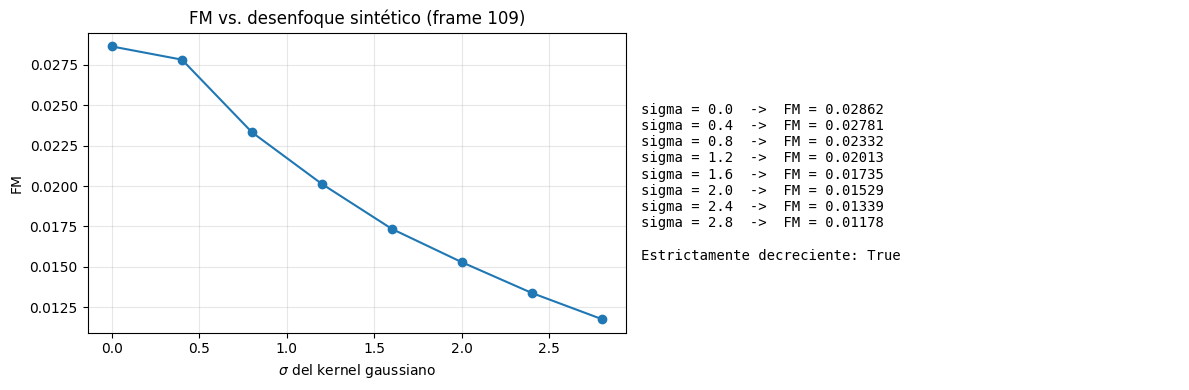

Caída de FM entre sigma=0 y sigma=2.8: 2.4x


In [7]:
sigmas = np.arange(0, 3.01, 0.4)
fm_sigmas = np.array([
    medida_enfoque(frame_ref if s == 0 else cv2.GaussianBlur(frame_ref, (0, 0), s))
    for s in sigmas
])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(sigmas, fm_sigmas, "o-", color="#1f77b4")
ax1.set_xlabel(r"$\sigma$ del kernel gaussiano")
ax1.set_ylabel("FM")
ax1.set_title(f"FM vs. desenfoque sintético (frame {idx_ref})")

monotona = bool(np.all(np.diff(fm_sigmas) < 0))
ax2.axis("off")
ax2.text(0.0, 0.5,
         "\n".join([f"sigma = {s:.1f}  ->  FM = {v:.5f}" for s, v in zip(sigmas, fm_sigmas)]
                   + ["", f"Estrictamente decreciente: {monotona}"]),
         family="monospace", va="center", fontsize=10)
plt.tight_layout(); plt.show()

print(f"Caída de FM entre sigma=0 y sigma={sigmas[-1]:.1f}: {fm_sigmas[0] / fm_sigmas[-1]:.1f}x")

FM decrece de forma estrictamente monótona, igual que en la figura 5(a) del paper.

### 3.2 La ecuación (1) contra el ejemplo numérico del paper

El paper publica en la sección 3.2 los valores para la imagen *Lena* de 512×512. Sirven para
confirmar sin ambigüedad cuál es la ecuación (1).

In [8]:
for nombre, TH_paper, FM_paper in [("Lena nítida", 4780, 0.0182), ("Lena borrosa", 1176, 0.0045)]:
    FM_calc = TH_paper / (512 * 512)
    print(f"{nombre:13s}  TH={TH_paper:5d}  FM(paper)={FM_paper:.4f}  "
          f"FM=TH/(M*N)={FM_calc:.4f}  -> coincide: {abs(FM_calc - FM_paper) < 5e-5}")

Lena nítida    TH= 4780  FM(paper)=0.0182  FM=TH/(M*N)=0.0182  -> coincide: True
Lena borrosa   TH= 1176  FM(paper)=0.0045  FM=TH/(M*N)=0.0045  -> coincide: True


### 3.3 ⚠️ FM **no** es comparable entre regiones de distinto tamaño

Este es un límite del método que conviene establecer antes de los experimentos, porque condiciona
qué comparaciones son válidas después.

Se toma **el mismo contenido visual** —la ROI central del frame más nítido— y se lo remuestrea a
distintos tamaños. Si la división por $M \cdot N$ normalizara realmente por tamaño, FM debería
mantenerse aproximadamente constante.

In [9]:
roi_ref, _ = roi_central(frames[idx_ref], 0.10)

print(f"{'escala':>8}{'tamaño':>14}{'píxeles':>10}{'FM':>10}")
print("-" * 42)
fm_escalas = []
for escala in [0.5, 1.0, 2.0]:
    interp = cv2.INTER_AREA if escala < 1 else cv2.INTER_CUBIC
    r = cv2.resize(roi_ref, None, fx=escala, fy=escala, interpolation=interp)
    v = medida_enfoque(r)
    fm_escalas.append(v)
    print(f"{escala:>8.1f}{f'{r.shape[1]}x{r.shape[0]}':>14}{r.size:>10}{v:>10.4f}")

print(f"\nVariación de FM con el MISMO contenido: {max(fm_escalas)/min(fm_escalas):.1f}x")

  escala        tamaño   píxeles        FM
------------------------------------------
     0.5        101x57      5757    0.8232
     1.0       202x114     23028    0.3537
     2.0       404x228     92112    0.0828

Variación de FM con el MISMO contenido: 9.9x


**Con el mismo contenido visual, FM varía un orden de magnitud según el tamaño de la región.** El
motivo es que al reducir el número de coeficientes el espectro se concentra, y una fracción mucho
mayor de ellos supera $M_{max}/1000$. La división por $M \cdot N$ normaliza la cuenta absoluta, pero
no la estadística del espectro.

🔑 **Por eso, en todo lo que sigue, las curvas de distinto tamaño se comparan por rango dinámico y
forma, nunca por su valor absoluto.** La sección 8 incluye además el control que separa el efecto
del tamaño del efecto del recorte.

---
<a id="4"></a>
## 4. Inspección visual: frames y espectros

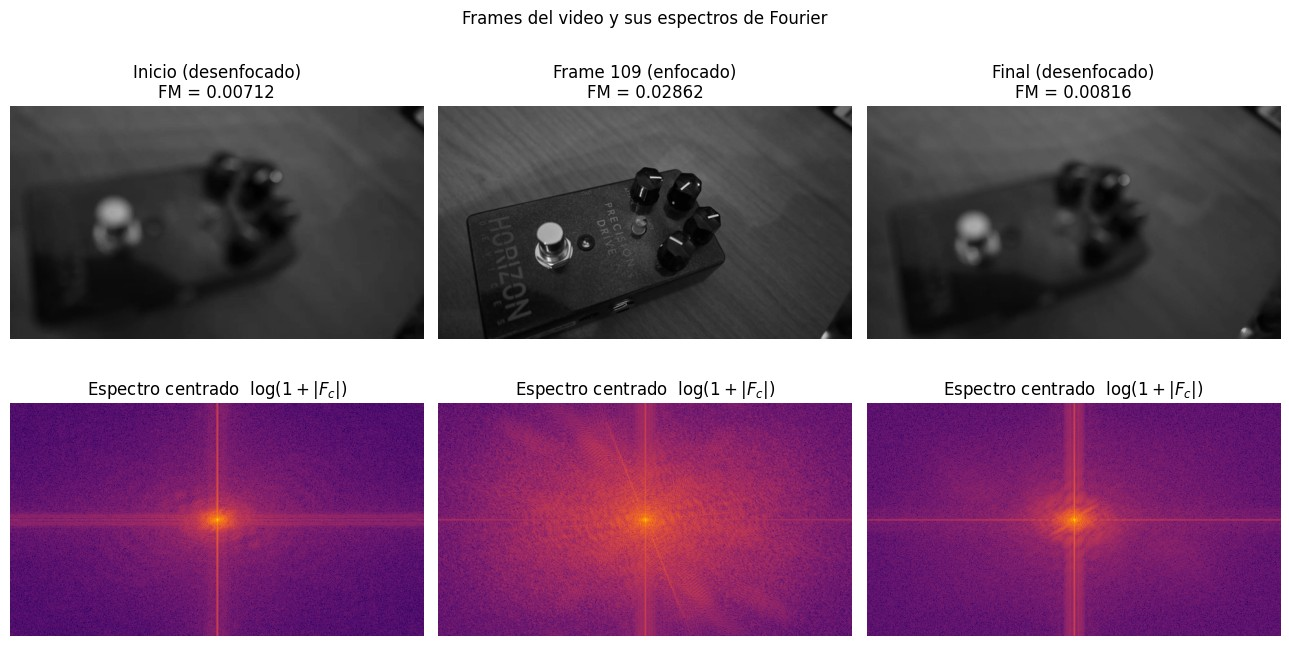

In [10]:
indices_muestra = [0, idx_ref, N_FRAMES - 1]
etiquetas = ["Inicio (desenfocado)", f"Frame {idx_ref} (enfocado)", "Final (desenfocado)"]

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for col, (i, etq) in enumerate(zip(indices_muestra, etiquetas)):
    axes[0, col].imshow(frames[i], cmap="gray", vmin=0, vmax=255)
    axes[0, col].set_title(f"{etq}\nFM = {fm_full[i]:.5f}")
    axes[0, col].axis("off")

    axes[1, col].imshow(espectro_log(frames[i]), cmap="inferno")
    axes[1, col].set_title("Espectro centrado  $\\log(1+|F_c|)$")
    axes[1, col].axis("off")

plt.suptitle("Frames del video y sus espectros de Fourier", y=0.99)
plt.tight_layout(); mostrar_jpeg(fig)

Se ve lo que predice la teoría: en el frame enfocado la energía se **dispersa hacia la periferia**
del espectro, mientras que en los frames desenfocados queda **concentrada en el centro**. Es la
observación de la figura 2 del paper.

También se aprecia la **cruz de leakage** sobre los ejes horizontal y vertical, presente en los tres
espectros. Es un artefacto de calcular la FFT sobre una imagen no periódica y se analiza en la
sección 9.

---
<a id="5"></a>
## 5. Experimento 1 — medición sobre todo el frame

La métrica aplicada a **cada frame completo** (calculada en la sección 3).

In [11]:
print(f"FM mínimo : {fm_full.min():.5f}  (frame {int(fm_full.argmin())})")
print(f"FM máximo : {fm_full.max():.5f}  (frame {int(fm_full.argmax())})")
print(f"Rango dinámico (max/min): {fm_full.max() / fm_full.min():.2f}x")

FM mínimo : 0.00682  (frame 15)
FM máximo : 0.02862  (frame 109)
Rango dinámico (max/min): 4.20x


---
<a id="6"></a>
## 6. Experimento 2 — medición sobre la ROI central

El enunciado pide una ROI centrada cuya área sea el **5% o el 10%** del área total. Se evalúan
**ambas** para poder compararlas.

Esta es la estrategia de las cámaras digitales: el autofoco no mide sobre toda la escena sino sobre
una región donde se presume que está el sujeto. El porqué se analiza en la sección 8.

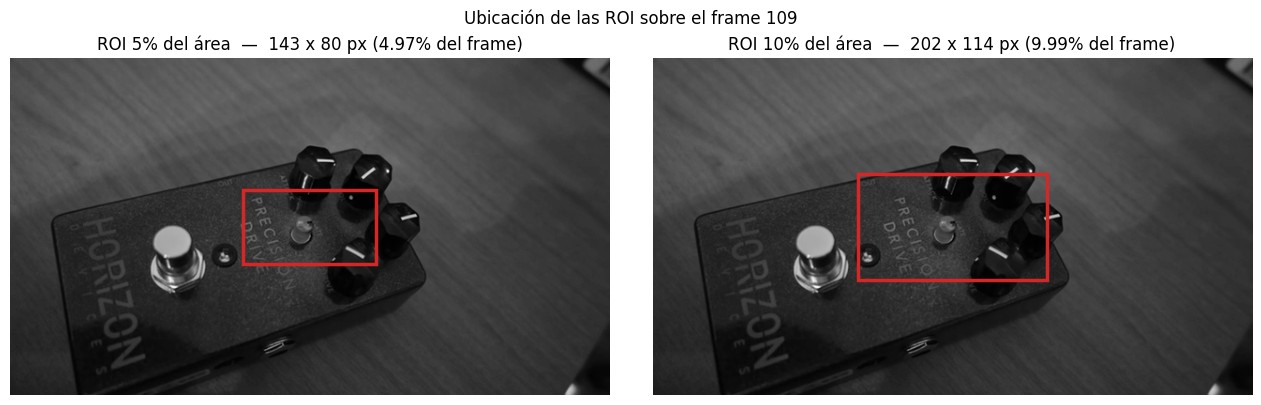

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, frac in zip(axes, [0.05, 0.10]):
    _, (x0, y0, rw, rh) = roi_central(frames[idx_ref], frac)
    ax.imshow(frames[idx_ref], cmap="gray", vmin=0, vmax=255)
    ax.add_patch(plt.Rectangle((x0, y0), rw, rh, edgecolor="#d62728", facecolor="none", lw=2.5))
    ax.set_title(f"ROI {frac:.0%} del área  —  {rw} x {rh} px "
                 f"({rw * rh / (W * H):.2%} del frame)")
    ax.axis("off")
plt.suptitle(f"Ubicación de las ROI sobre el frame {idx_ref}", y=1.0)
plt.tight_layout(); mostrar_jpeg(fig)

In [13]:
fm_roi = {}
for frac in [0.05, 0.10]:
    fm_roi[frac] = curva_fm(frames, lambda f, fr=frac: roi_central(f, fr)[0])
    a = fm_roi[frac]
    print(f"ROI {frac:.0%}  ->  min={a.min():.5f}  max={a.max():.5f} (frame {int(a.argmax())})  "
          f"rango dinámico={a.max() / a.min():.2f}x")

ROI 5%  ->  min=0.05481  max=0.46591 (frame 111)  rango dinámico=8.50x


ROI 10%  ->  min=0.04295  max=0.35939 (frame 111)  rango dinámico=8.37x


---
<a id="7"></a>
## 7. Detección automática de la región de máximo enfoque

Requisito central del enunciado: **la región de máximo enfoque debe detectarse de forma automática**,
sin elegirla a ojo ni hardcodear índices de frame.

### Criterio

No alcanza con devolver `argmax`: el enfoque no es un instante puntual sino un **intervalo** en el
que la imagen está aceptablemente nítida. El criterio implementado es:

1. **Suavizar** la curva con una media móvil corta (5 frames ≈ 0,17 s) con padding por reflexión,
   para que el pico no lo fije un outlier de un único frame.
2. Tomar como **pico** el `argmax` de la curva suavizada.
3. Fijar el umbral en una **fracción relativa del máximo**, $u = 0{,}90 \cdot FM_{max}$.
4. Devolver el **intervalo contiguo alrededor del pico** donde la curva supera ese umbral.

### Por qué el umbral es relativo y no absoluto

Por lo establecido en la sección 3.3, los niveles absolutos de FM del frame completo y de las ROI
difieren en un orden de magnitud. Un umbral absoluto no podría servir para las tres curvas. Uno
**relativo al máximo de cada curva** se adapta solo, que es lo que permite que la misma función
resuelva los tres casos sin tocar ningún parámetro.

In [14]:
def media_movil(x, ventana):
    """Media móvil centrada con padding por reflexión (no deforma los extremos)."""
    if ventana <= 1:
        return np.asarray(x, dtype=float)
    if ventana % 2 == 0:
        raise ValueError("La ventana debe ser impar para que la media móvil sea centrada")
    k = ventana // 2
    xp = np.pad(np.asarray(x, dtype=float), k, mode="reflect")
    return np.convolve(xp, np.ones(ventana) / ventana, mode="valid")


def detectar_region_enfoque(fm_curva, umbral_rel=UMBRAL_REL, ventana=VENTANA_SUAVIZADO):
    """Detecta automáticamente el pico y la región de máximo enfoque de una curva FM.

    Parameters
    ----------
    fm_curva : ndarray 1-D
        Valor de FM por frame.
    umbral_rel : float
        Fracción del máximo que define el borde de la región.
    ventana : int
        Ventana impar de la media móvil usada para localizar el pico de forma robusta.

    Returns
    -------
    dict con: pico, inicio, fin (inclusive), umbral, mascara, suave
    """
    fm_curva = np.asarray(fm_curva, dtype=float)
    suave = media_movil(fm_curva, ventana)

    pico = int(np.argmax(suave))
    umbral = umbral_rel * suave[pico]

    inicio = pico
    while inicio > 0 and suave[inicio - 1] >= umbral:
        inicio -= 1
    fin = pico
    while fin < len(suave) - 1 and suave[fin + 1] >= umbral:
        fin += 1

    mascara = np.zeros(len(fm_curva), dtype=bool)
    mascara[inicio:fin + 1] = True

    return {"pico": pico, "inicio": inicio, "fin": fin, "umbral": float(umbral),
            "mascara": mascara, "suave": suave}

In [15]:
curvas = {
    "Frame completo": fm_full,
    "ROI 10%": fm_roi[0.10],
    "ROI 5%": fm_roi[0.05],
}
deteccion = {nombre: detectar_region_enfoque(c) for nombre, c in curvas.items()}

encabezado = f"{'Curva':<16}{'pico':>6}{'t pico [s]':>12}{'región':>14}{'duración':>11}{'umbral':>11}"
print(encabezado); print("-" * len(encabezado))
for nombre, d in deteccion.items():
    region = "[{}, {}]".format(d["inicio"], d["fin"])
    print(f"{nombre:<16}{d['pico']:>6}{t[d['pico']]:>12.2f}{region:>14}"
          f"{(d['fin'] - d['inicio'] + 1) / FPS:>10.2f}s{d['umbral']:>11.5f}")

Curva             pico  t pico [s]        región   duración     umbral
----------------------------------------------------------------------
Frame completo     109        3.64     [79, 115]      1.23s    0.02555
ROI 10%            111        3.70    [100, 113]      0.47s    0.31460
ROI 5%             111        3.70     [92, 113]      0.73s    0.40739


### El suavizado no mueve el pico

Vale la pena verificarlo en lugar de asumirlo: si el `argmax` crudo y el suavizado coinciden, es
evidencia de que **el máximo no es un outlier** y de que el suavizado no está introduciendo un sesgo.

In [16]:
print(f"{'Curva':<16}{'argmax crudo':>14}{'argmax suavizado':>19}{'coinciden':>12}")
print("-" * 61)
for nombre, curva in curvas.items():
    crudo = int(np.argmax(curva))
    suave = int(np.argmax(media_movil(curva, VENTANA_SUAVIZADO)))
    print(f"{nombre:<16}{crudo:>14}{suave:>19}{str(crudo == suave):>12}")

Curva             argmax crudo   argmax suavizado   coinciden
-------------------------------------------------------------
Frame completo             109                109        True
ROI 10%                    111                111        True
ROI 5%                     111                111        True


### Curvas con la región de máximo enfoque marcada

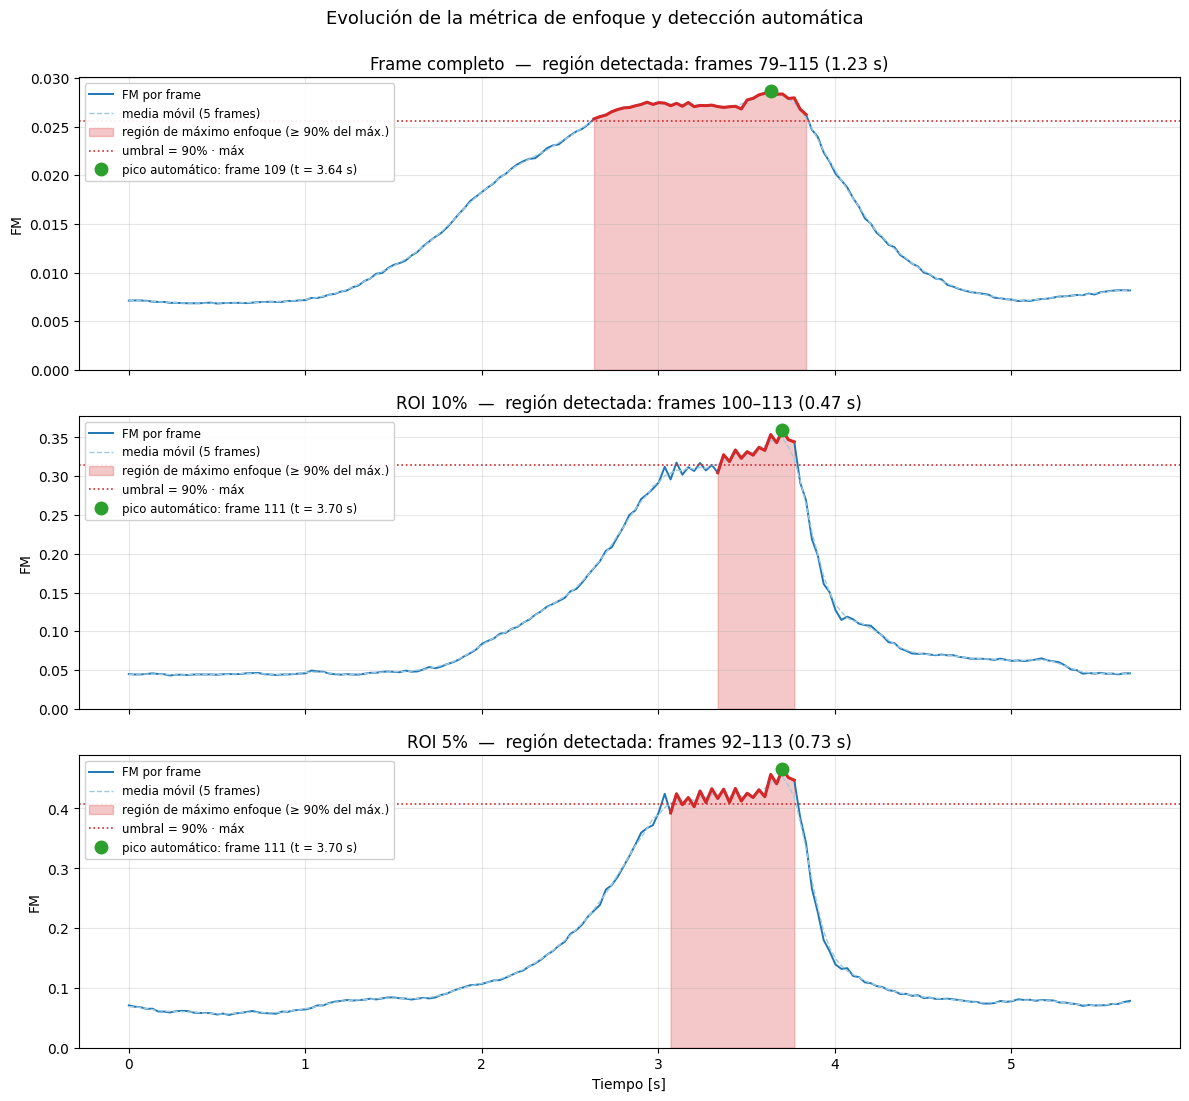

In [17]:
COLOR_CURVA = "#1f77b4"
COLOR_REGION = "#d62728"   # color distinto para la región de máximo enfoque
COLOR_PICO = "#2ca02c"

fig, axes = plt.subplots(3, 1, figsize=(12, 11), sharex=True)

for ax, (nombre, curva) in zip(axes, curvas.items()):
    d = deteccion[nombre]

    ax.plot(t, curva, color=COLOR_CURVA, lw=1.4, label="FM por frame")
    ax.plot(t, d["suave"], color="#9ecae1", lw=1.0, ls="--",
            label=f"media móvil ({VENTANA_SUAVIZADO} frames)")

    ax.fill_between(t, 0, curva, where=d["mascara"], color=COLOR_REGION, alpha=0.25,
                    label=f"región de máximo enfoque (≥ {UMBRAL_REL:.0%} del máx.)")
    ax.plot(t[d["mascara"]], curva[d["mascara"]], color=COLOR_REGION, lw=2.2)

    ax.axhline(d["umbral"], color=COLOR_REGION, ls=":", lw=1.2,
               label=f"umbral = {UMBRAL_REL:.0%} · máx")
    ax.plot(t[d["pico"]], curva[d["pico"]], "o", color=COLOR_PICO, ms=9, zorder=5,
            label=f"pico automático: frame {d['pico']} (t = {t[d['pico']]:.2f} s)")

    ax.set_title(f"{nombre}  —  región detectada: frames {d['inicio']}–{d['fin']} "
                 f"({(d['fin'] - d['inicio'] + 1) / FPS:.2f} s)")
    ax.set_ylabel("FM")
    ax.set_ylim(bottom=0)
    ax.legend(loc="upper left", fontsize=8.5, framealpha=0.92)

axes[-1].set_xlabel("Tiempo [s]")
plt.suptitle("Evolución de la métrica de enfoque y detección automática", y=0.997, fontsize=13)
plt.tight_layout(); plt.show()

### Las tres curvas superpuestas

Por lo visto en 3.3, los niveles absolutos no son comparables, así que para poder verlas en un mismo
gráfico se normaliza cada curva por su propio máximo. Lo que se compara acá es **la forma**.

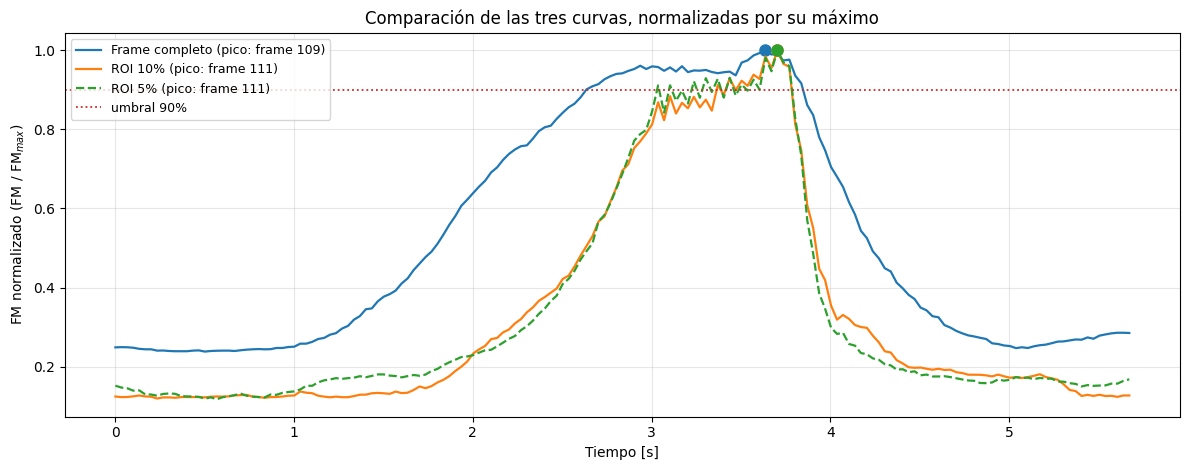

In [18]:
fig, ax = plt.subplots(figsize=(12, 4.8))
estilos = {"Frame completo": ("#1f77b4", "-"), "ROI 10%": ("#ff7f0e", "-"), "ROI 5%": ("#2ca02c", "--")}

for nombre, curva in curvas.items():
    color, ls = estilos[nombre]
    d = deteccion[nombre]
    ax.plot(t, curva / curva.max(), color=color, ls=ls, lw=1.6,
            label=f"{nombre} (pico: frame {d['pico']})")
    ax.plot(t[d["pico"]], 1.0, "o", color=color, ms=8)

ax.axhline(UMBRAL_REL, color="#d62728", ls=":", lw=1.3, label=f"umbral {UMBRAL_REL:.0%}")
ax.set_xlabel("Tiempo [s]"); ax.set_ylabel("FM normalizado (FM / FM$_{max}$)")
ax.set_title("Comparación de las tres curvas, normalizadas por su máximo")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()

### Sensibilidad al umbral

In [19]:
umbrales = [0.80, 0.85, 0.90, 0.95, 0.99]
print(f"{'umbral':>8} | " + " | ".join(f"{n:^24}" for n in curvas))
print("-" * 88)
for u in umbrales:
    celdas = []
    for nombre, curva in curvas.items():
        d = detectar_region_enfoque(curva, umbral_rel=u)
        celdas.append(f"pico {d['pico']:3d}, [{d['inicio']:3d},{d['fin']:3d}] "
                      f"{(d['fin'] - d['inicio'] + 1) / FPS:4.2f}s")
    print(f"{u:>8.0%} | " + " | ".join(f"{c:^24}" for c in celdas))

  umbral |      Frame completo      |         ROI 10%          |          ROI 5%         
----------------------------------------------------------------------------------------
     80% | pico 109, [ 72,117] 1.53s | pico 111, [ 89,114] 0.87s | pico 111, [ 88,114] 0.90s
     85% | pico 109, [ 76,116] 1.37s | pico 111, [ 91,113] 0.77s | pico 111, [ 90,113] 0.80s
     90% | pico 109, [ 79,115] 1.23s | pico 111, [100,113] 0.47s | pico 111, [ 92,113] 0.73s
     95% | pico 109, [ 85,113] 0.97s | pico 111, [107,112] 0.20s | pico 111, [107,112] 0.20s
     99% | pico 109, [107,111] 0.17s | pico 111, [110,111] 0.07s | pico 111, [111,111] 0.03s


### ⚠️ El pico es robusto; el ancho de la región, no

Hay que leer esta tabla con cuidado, porque dice dos cosas distintas:

- **El pico no depende del umbral en absoluto.** Frames 109 / 111 / 111 para los cinco umbrales
  probados, del 80% al 99%. Esta es la salida principal del detector y es sólida.
- **El ancho sí es sensible, y no de forma suave.** Para la ROI 10%, entre el 85% y el 90% el inicio
  de la región **salta 9 frames de golpe** (91 → 100) y la duración cae un 39%, mientras que la
  ROI 5% apenas se mueve en ese mismo tramo.

La causa no es ruido ni un mínimo local: es que la curva tiene un **hombro largo y casi plano** justo
por debajo del umbral. Conviene mirar los valores.

In [20]:
d10 = deteccion["ROI 10%"]
suave10 = d10["suave"]
umbral10 = d10["umbral"]

print(f"ROI 10% — curva suavizada cerca del umbral ({umbral10:.4f})\n")
print(f"{'frame':>7}{'FM suave':>11}{'% del máx':>12}{'estado':>10}")
print("-" * 40)
for i in range(88, 104):
    pct = 100 * suave10[i] / suave10[d10["pico"]]
    print(f"{i:>7}{suave10[i]:>11.4f}{pct:>11.1f}%{'≥ umbral' if suave10[i] >= umbral10 else '< umbral':>10}")

pendiente = np.abs(np.diff(suave10[88:104])).mean()
print(f"\nPendiente media en el hombro (frames 88–103): {pendiente:.5f} FM/frame")
print(f"Pendiente media en el flanco de bajada (frames 114–125): "
      f"{np.abs(np.diff(suave10[114:126])).mean():.5f} FM/frame")

ROI 10% — curva suavizada cerca del umbral (0.3146)

  frame   FM suave   % del máx    estado
----------------------------------------
     88     0.2758       78.9%  < umbral
     89     0.2871       82.1%  < umbral
     90     0.2921       83.6%  < umbral
     91     0.3003       85.9%  < umbral
     92     0.3040       87.0%  < umbral
     93     0.3078       88.1%  < umbral
     94     0.3068       87.8%  < umbral
     95     0.3110       89.0%  < umbral
     96     0.3090       88.4%  < umbral
     97     0.3115       89.1%  < umbral
     98     0.3101       88.7%  < umbral
     99     0.3143       89.9%  < umbral
    100     0.3146       90.0%  ≥ umbral
    101     0.3199       91.5%  ≥ umbral
    102     0.3216       92.0%  ≥ umbral
    103     0.3271       93.6%  ≥ umbral

Pendiente media en el hombro (frames 88–103): 0.00402 FM/frame
Pendiente media en el flanco de bajada (frames 114–125): 0.01691 FM/frame


**Diagnóstico.** Entre los frames 91 y 99 la curva suavizada apenas se mueve: de 0,3003 a 0,3143, o
sea del 85,9% al 89,9% del máximo, con el umbral puesto en el 90%. Los cinco frames del tramo 95–99
se mantienen **entre el 88,4% y el 89,9%**, es decir a menos de **1,7 puntos porcentuales** del umbral
sin llegar a cruzarlo. La pendiente en ese hombro es **cuatro veces menor** que en el flanco de
bajada (0,0040 contra 0,0169 FM/frame). En una zona tan plana, **el cruce con cualquier umbral
horizontal está mal condicionado**: un desplazamiento mínimo del umbral mueve la frontera muchos
frames.

Esto **no se arregla con histéresis**, y conviene ser preciso sobre el motivo. La histéresis sirve
cuando ya se está *dentro* de la región y la curva se sale brevemente: tolera ese cruce y sigue. Acá
el problema es otro: **el hombro entero queda por debajo del umbral**, de modo que el crecimiento de
la región nunca llega a entrar en él y no hay cruce que tolerar. Se verificó experimentalmente —con
tolerancias de 1 a 4 frames no cambia ningún resultado—. Las oscilaciones locales que sí tiene la
curva (baja en los frames 94, 96 y 98) son de amplitud despreciable frente a la distancia al umbral.
Es una propiedad de los datos, no del detector.

**Qué se hace al respecto.** Se reporta el **pico** como la salida principal del detector —que es lo
que pide el enunciado y es robusto— y el intervalo como una indicación cuyo borde inferior tiene una
incertidumbre de varios frames en el caso de la ROI 10%. Un consumidor de esta métrica que necesite
un ancho estable debería usar un criterio de ancho a mitad de altura o reportarlo con su
incertidumbre, en lugar de un umbral cercano al máximo.

---
<a id="8"></a>
## 8. Comparación de los dos experimentos

In [21]:
filas = []
for nombre, curva in curvas.items():
    d = deteccion[nombre]
    filas.append({
        "Medición": nombre,
        "FM min": curva.min(),
        "FM max": curva.max(),
        "Rango dinámico": curva.max() / curva.min(),
        "Frame pico": d["pico"],
        "Región": f"[{d['inicio']}, {d['fin']}]",
        "Duración [s]": (d["fin"] - d["inicio"] + 1) / FPS,
    })

tabla = pd.DataFrame(filas).set_index("Medición")
print(tabla.to_string(float_format=lambda v: f"{v:.5f}"))

                FM min  FM max  Rango dinámico  Frame pico      Región  Duración [s]
Medición                                                                            
Frame completo 0.00682 0.02862         4.19796         109   [79, 115]       1.23457
ROI 10%        0.04295 0.35939         8.36805         111  [100, 113]       0.46713
ROI 5%         0.05481 0.46591         8.50080         111   [92, 113]       0.73407


### 8.1 Control: ¿el recorte, o simplemente tener menos píxeles?

La ROI discrimina mejor que el frame completo. Pero la sección 3.3 mostró que FM depende del tamaño,
así que esa comparación mezcla dos efectos: el de **mirar solo el sujeto** y el de **tener menos
píxeles**. Hay que separarlos.

El control es directo: medir el **frame completo remuestreado al tamaño exacto de la ROI 10%**
(202×114). Tiene el mismo número de píxeles que la ROI, pero el mismo campo visual que el frame
completo.

⚠️ El remuestreo con `INTER_AREA` promedia píxeles, o sea que actúa como un pasabajos y penaliza algo
al frame completo. El sesgo va en contra de la hipótesis que se quiere sostener, así que si aun así
la ROI gana, la conclusión vale *a fortiori*.

In [22]:
_, (_, _, RW10, RH10) = roi_central(frames[idx_ref], 0.10)
fm_full_remuestreado = curva_fm(
    frames, lambda f: cv2.resize(f, (RW10, RH10), interpolation=cv2.INTER_AREA))

comparacion = [
    ("Frame completo", f"{W}x{H}", fm_full),
    ("Frame completo remuestreado", f"{RW10}x{RH10}", fm_full_remuestreado),
    ("ROI 10%", f"{RW10}x{RH10}", fm_roi[0.10]),
]
print(f"{'Medición':<30}{'tamaño':>12}{'rango dinámico':>17}{'pico':>7}")
print("-" * 66)
for nombre, tam, c in comparacion:
    print(f"{nombre:<30}{tam:>12}{c.max() / c.min():>16.2f}x{int(np.argmax(media_movil(c, VENTANA_SUAVIZADO))):>7}")

Medición                            tamaño   rango dinámico   pico
------------------------------------------------------------------
Frame completo                     640x360            4.20x    109
Frame completo remuestreado        202x114            3.67x    108
ROI 10%                            202x114            8.37x    111


🔑 **El efecto es del recorte, no del tamaño.** A igual número de píxeles, la ROI discrimina más del
doble que el cuadro completo. De hecho, remuestrear el frame completo **empeora** levemente su rango
dinámico, con lo cual la ventaja de la ROI queda subestimada, no inflada, en la comparación original.

### 8.2 ¿Por qué el frame completo discrimina peor?

La explicación intuitiva sería que el fondo aporta un piso constante de altas frecuencias que diluye
la señal. **Conviene verificarla en lugar de asumirla**, porque resulta ser incorrecta.

Se miden dos regiones del **mismo tamaño** que la ROI 10% pero ubicadas en las esquinas, es decir,
puro fondo.

In [23]:
regiones_fondo = {
    "Esquina sup-izq": (0, 0),
    "Esquina inf-der": (H - RH10, W - RW10),
    "ROI central": ((H - RH10) // 2, (W - RW10) // 2),
}

print(f"{'Región ' + f'{RW10}x{RH10}':<20}{'FM min':>10}{'FM max':>10}{'rango':>9}{'pico':>7}")
print("-" * 56)
curvas_fondo = {}
for nombre, (y0, x0) in regiones_fondo.items():
    c = curva_fm(frames, lambda f, y=y0, x=x0: f[y:y + RH10, x:x + RW10])
    curvas_fondo[nombre] = c
    pico = int(np.argmax(media_movil(c, VENTANA_SUAVIZADO)))
    print(f"{nombre:<20}{c.min():>10.4f}{c.max():>10.4f}{c.max() / c.min():>8.2f}x{pico:>7}")

Región 202x114          FM min    FM max    rango   pico
--------------------------------------------------------


Esquina sup-izq         0.0083    0.0302    3.64x     69


Esquina inf-der         0.0253    0.0885    3.50x    118


ROI central             0.0429    0.3594    8.37x    111


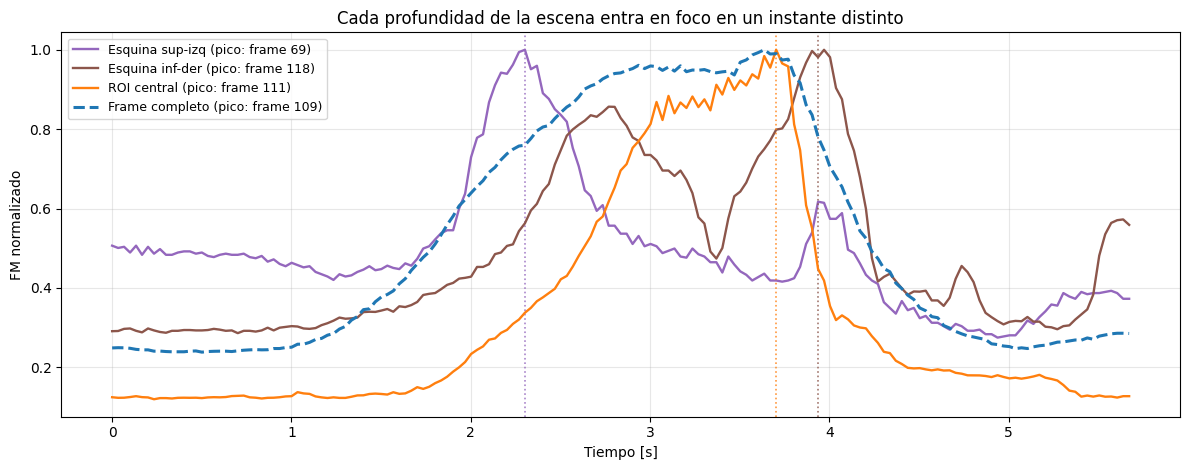

In [24]:
fig, ax = plt.subplots(figsize=(12, 4.8))
colores_fondo = {"Esquina sup-izq": "#9467bd", "Esquina inf-der": "#8c564b", "ROI central": "#ff7f0e"}

for nombre, c in curvas_fondo.items():
    pico = int(np.argmax(media_movil(c, VENTANA_SUAVIZADO)))
    ax.plot(t, c / c.max(), color=colores_fondo[nombre], lw=1.7,
            label=f"{nombre} (pico: frame {pico})")
    ax.axvline(t[pico], color=colores_fondo[nombre], ls=":", lw=1.2, alpha=0.8)

ax.plot(t, fm_full / fm_full.max(), color="#1f77b4", lw=2.2, ls="--",
        label=f"Frame completo (pico: frame {int(np.argmax(media_movil(fm_full, VENTANA_SUAVIZADO)))})")

ax.set_xlabel("Tiempo [s]"); ax.set_ylabel("FM normalizado")
ax.set_title("Cada profundidad de la escena entra en foco en un instante distinto")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()

🔑 **El fondo no es un piso constante: también entra en foco, pero en otro momento.** Las dos
esquinas tienen rangos dinámicos de 3,5–3,6x —lejos de ser constantes— y sus picos caen en los
frames **69** y **118**, contra el frame **111** del sujeto central.

El video es un **barrido focal**: a medida que el plano focal se desplaza, cada profundidad de la
escena pasa por su propio óptimo. La curva del frame completo no es entonces "señal + piso", sino la
**superposición de varios picos desplazados en el tiempo**, uno por cada profundidad presente en el
cuadro.

Eso explica las dos cosas que se observan:

- **La meseta es mucho más ancha** (37 frames contra 14 de la ROI): es la envolvente de picos que
  ocurren en instantes distintos.
- **El pico aparece corrido** (frame 109 contra 111): está desplazado hacia el promedio ponderado de
  las profundidades de la escena, no en el óptimo del sujeto.

Dicho de otro modo, medir sobre el cuadro completo no *diluye* la señal de enfoque: **mide una
magnitud distinta** —el enfoque promedio de la escena— que no es la que el autofoco necesita.

### 8.3 ROI del 5% vs. del 10%

Las dos ROI dan el mismo pico. La del 5% tiene un rango dinámico apenas mayor, pero es **más
ruidosa**: con menos píxeles, el espectro se estima con más varianza. Se cuantifica midiendo la
dispersión del residuo respecto de la curva suavizada.

In [25]:
print(f"{'Curva':<16}{'píxeles':>10}{'ruido relativo':>17}{'región':>12}{'dur [s]':>9}")
print("-" * 64)
for frac in [0.05, 0.10]:
    c = fm_roi[frac]
    _, (_, _, rw, rh) = roi_central(frames[idx_ref], frac)
    residuo = c - media_movil(c, VENTANA_SUAVIZADO)
    d = deteccion[f"ROI {frac:.0%}"]
    region = "[{},{}]".format(d["inicio"], d["fin"])
    print(f"{f'ROI {frac:.0%}':<16}{rw * rh:>10}{residuo.std() / c.mean():>17.4f}"
          f"{region:>12}{(d['fin'] - d['inicio'] + 1) / FPS:>9.2f}")

Curva              píxeles   ruido relativo      región  dur [s]
----------------------------------------------------------------
ROI 5%               11440           0.0330    [92,113]     0.73
ROI 10%              23028           0.0284   [100,113]     0.47


La ROI del 5% tiene un **16% más de ruido relativo**, con la mitad de píxeles. Eso confirma la
expectativa.

⚠️ **Una aparente contradicción que conviene aclarar:** la ROI del 5% devuelve una región *más ancha*
(0,73 s) que la del 10% (0,47 s), lo que podría leerse como que está peor definida. **No es así:** por
lo visto en la sección 7, la región de la ROI 10% es justamente la que cae en la zona mal
condicionada del umbral. Con un umbral del 85% las dos dan prácticamente lo mismo (0,77 s y 0,80 s).
La diferencia es un artefacto del punto de operación elegido, no una propiedad de las regiones.

**Conclusión práctica:** la ROI del **10% es el mejor compromiso** —mismo poder de discriminación con
la mitad del ruido—, y el ancho de su región debe reportarse con la salvedad de la sección 7.

---
<a id="9"></a>
## 9. Sensibilidad al preprocesamiento: leakage espectral

El paper no lo menciona, así que **esto excede la consigna**, pero es la sensibilidad más grande del
método y dejarla sin explorar daría una falsa impresión de robustez.

La FFT asume que la señal es **periódica**. Una imagen real no lo es: hay un salto brusco entre el
borde derecho y el izquierdo, y entre el superior y el inferior. Ese salto artificial genera la
**cruz de leakage** visible sobre los ejes de los espectros de la sección 4, y esas componentes
espurias **también cuentan para TH**.

La forma estándar de mitigarlo es multiplicar la imagen por una **ventana** que decaiga suavemente a
cero en los bordes. Se prueba con una ventana de Hann separable.

In [26]:
def ventana_hann_2d(shape):
    """Ventana de Hann 2-D separable, del tamaño de la imagen."""
    return np.outer(np.hanning(shape[0]), np.hanning(shape[1]))


def aplicar_ventana(imagen):
    img = np.asarray(imagen, dtype=np.float64)
    return img * ventana_hann_2d(img.shape)

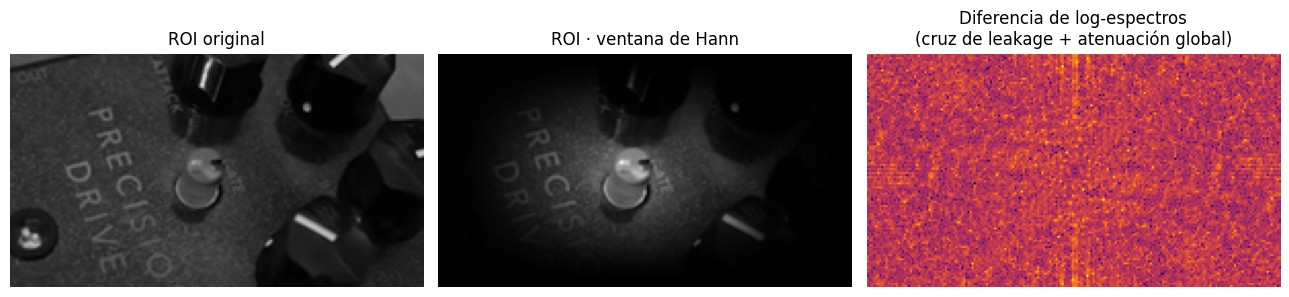

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
roi_pico, _ = roi_central(frames[idx_ref], 0.10)
axes[0].imshow(roi_pico, cmap="gray", vmin=0, vmax=255); axes[0].set_title("ROI original")
axes[1].imshow(aplicar_ventana(roi_pico), cmap="gray"); axes[1].set_title("ROI · ventana de Hann")
axes[2].imshow(espectro_log(roi_pico) - espectro_log(aplicar_ventana(roi_pico)), cmap="inferno")
axes[2].set_title("Diferencia de log-espectros\n(cruz de leakage + atenuación global)")
for a in axes: a.axis("off")
plt.tight_layout(); mostrar_jpeg(fig)

In [28]:
print(f"{'Medición':<18}{'sin ventana':>26}{'con Hann':>26}")
print(f"{'':<18}{'rango':>14}{'pico':>12}{'rango':>14}{'pico':>12}")
print("-" * 70)
fm_hann = {}
for nombre, base, getter in [
    ("ROI 10%", fm_roi[0.10], lambda f: roi_central(f, 0.10)[0]),
    ("Frame completo", fm_full, lambda f: f),
]:
    c = curva_fm(frames, lambda f, g=getter: aplicar_ventana(g(f)))
    fm_hann[nombre] = c
    p_base = int(np.argmax(media_movil(base, VENTANA_SUAVIZADO)))
    p_hann = int(np.argmax(media_movil(c, VENTANA_SUAVIZADO)))
    print(f"{nombre:<18}{base.max()/base.min():>13.2f}x{p_base:>12}"
          f"{c.max()/c.min():>13.2f}x{p_hann:>12}")

Medición                         sin ventana                  con Hann
                           rango        pico         rango        pico
----------------------------------------------------------------------


ROI 10%                    8.37x         111        27.66x          99


Frame completo             4.20x         109        14.68x          99


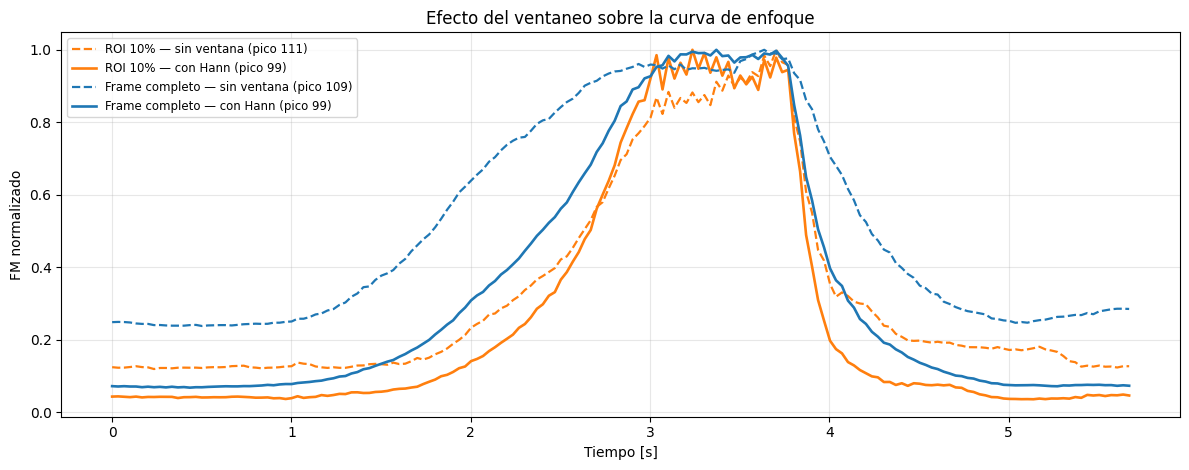

In [29]:
fig, ax = plt.subplots(figsize=(12, 4.8))
for nombre, color in [("ROI 10%", "#ff7f0e"), ("Frame completo", "#1f77b4")]:
    base = fm_roi[0.10] if nombre == "ROI 10%" else fm_full
    ax.plot(t, base / base.max(), color=color, lw=1.6, ls="--",
            label=f"{nombre} — sin ventana (pico {int(np.argmax(media_movil(base, VENTANA_SUAVIZADO)))})")
    ax.plot(t, fm_hann[nombre] / fm_hann[nombre].max(), color=color, lw=1.9,
            label=f"{nombre} — con Hann (pico {int(np.argmax(media_movil(fm_hann[nombre], VENTANA_SUAVIZADO)))})")
ax.set_xlabel("Tiempo [s]"); ax.set_ylabel("FM normalizado")
ax.set_title("Efecto del ventaneo sobre la curva de enfoque")
ax.legend(loc="upper left", fontsize=8.5)
plt.tight_layout(); plt.show()

### Lectura del resultado

**El ventaneo triplica el rango dinámico.** Eliminar la cruz de leakage saca del conteo una
contribución que estaba presente en todos los frames por igual, y la métrica gana muchísimo
contraste: de 8,4x a 27,7x en la ROI 10%.

**Pero el pico se corre 12 frames** (111 → 99), y eso obliga a matizar la conclusión de la sección 7.

⚠️ **Interpretación honesta.** No se puede afirmar que uno de los dos picos sea "el correcto" sin una
referencia externa, porque la ventana de Hann **no solo elimina leakage: también re-pondera el
contenido** hacia el centro de la región, atenuando los píxeles periféricos. Con lo medido acá no se
puede separar un efecto del otro.

Lo que sí queda establecido, y es lo que importa:

> **La robustez del pico demostrada en la sección 7 es robustez frente al *umbral de detección*, no
> frente al *preprocesamiento espectral*.** La elección de ventanear o no es una decisión de diseño
> que afecta el resultado más que cualquier parámetro del detector.

Como el enunciado pide implementar la métrica **tal como está en el paper**, y el paper no ventanea,
**los resultados reportados en las secciones 5 a 8 son los que corresponden a la consigna**. Esta
sección queda como análisis de sensibilidad, no como corrección de aquellos.

---
<a id="10"></a>
## 10. ⭐ Puntos extra — unsharp masking

### 10.1 Cómo funciona

El *unsharp masking* es la técnica clásica de realce vista en la clase 3. Se apoya en que restarle a
una imagen su versión pasa bajos deja las altas frecuencias:

$$\text{máscara} = I - G_\sigma(I) \qquad\qquad I_{sharp} = I + \alpha \cdot \text{máscara}$$

que reordenado es:

$$I_{sharp} = (1+\alpha)\, I - \alpha\, G_\sigma(I)$$

donde $G_\sigma$ es el desenfoque gaussiano y $\alpha$ la ganancia del realce. Como FM cuenta
componentes de alta frecuencia, amplificarlas debería subirla.

Hay **dos** parámetros y los dos importan: $\alpha$ controla *cuánto* se amplifica, y $\sigma$ decide
*qué banda* se amplifica —y por lo tanto incide directamente sobre una métrica que cuenta
coeficientes por encima de un umbral—. Se barren ambos antes de elegir.

In [30]:
def unsharp_masking(imagen, sigma, amount):
    """Realce de nitidez por unsharp masking, en punto flotante (sin saturación).

    I_sharp = (1 + amount) * I - amount * G_sigma(I)

    Parameters
    ----------
    sigma : float
        Desvío del kernel gaussiano; define qué se considera "baja frecuencia".
    amount : float
        Ganancia del realce. amount=0 devuelve la imagen original.

    Returns
    -------
    ndarray float64 — puede salirse del rango [0, 255]; usar `a_uint8` para mostrar.
    """
    img = np.asarray(imagen, dtype=np.float64)
    suave = cv2.GaussianBlur(img, (0, 0), sigma)
    return (1.0 + amount) * img - amount * suave


def a_uint8(imagen):
    """Convierte a uint8 recortando a [0, 255]. Solo para visualización."""
    return np.clip(imagen, 0, 255).astype(np.uint8)


def fraccion_fuera_de_rango(imagen):
    """Fracción de píxeles que quedarían recortados al convertir a uint8."""
    img = np.asarray(imagen)
    return np.count_nonzero((img < 0) | (img > 255)) / img.size

### 10.2 Barrido bidimensional de $\sigma$ y $\alpha$

Se recorren 3 valores de $\sigma$ por 7 de $\alpha$ (21 combinaciones), midiendo sobre la ROI 10%.
El criterio de selección es el **rango dinámico**, que es la magnitud que determina la capacidad de
discriminar enfocado de desenfocado. Se registran además los **halos** —fracción de píxeles que se
sale del rango representable— para poder evaluar el costo visual.

⚠️ A diferencia del resto de las columnas, que son estadísticos sobre los 171 frames, la de halos
se mide sobre un único frame: el más nítido, que es el caso más desfavorable por ser el de mayor
detalle. Sirve como indicador comparativo entre combinaciones, no como un promedio del video.

In [31]:
sigmas_us = [0.8, 1.5, 3.0]
amounts = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 5.0]

resultados = {}
for s in sigmas_us:
    fila_r = []
    for a in amounts:
        c = curva_fm(frames, lambda f, ss=s, aa=a: roi_central(unsharp_masking(f, ss, aa), 0.10)[0])
        d = detectar_region_enfoque(c)
        halos = fraccion_fuera_de_rango(roi_central(unsharp_masking(frames[idx_ref], s, a), 0.10)[0])
        fila_r.append({"sigma": s, "amount": a, "rango": c.max() / c.min(), "max": c.max(),
                       "min": c.min(), "pico": d["pico"], "halos": halos,
                       "dur": (d["fin"] - d["inicio"] + 1) / FPS})
    resultados[s] = fila_r

print(f"{'sigma':>7}{'amount':>8}{'FM max':>10}{'FM min':>10}{'rango':>9}{'pico':>7}{'dur [s]':>9}{'halos':>9}")
print("-" * 69)
for s in sigmas_us:
    for r in resultados[s]:
        print(f"{r['sigma']:>7.1f}{r['amount']:>8.1f}{r['max']:>10.4f}{r['min']:>10.4f}"
              f"{r['rango']:>8.2f}x{r['pico']:>7}{r['dur']:>9.2f}{r['halos']:>8.2%}")
    print()

picos_unicos = sorted({r["pico"] for s in sigmas_us for r in resultados[s]})
print(f"Picos detectados en las {len(sigmas_us)*len(amounts)} combinaciones: {picos_unicos}")

  sigma  amount    FM max    FM min    rango   pico  dur [s]    halos
---------------------------------------------------------------------
    0.8     0.0    0.3594    0.0429    8.37x    111     0.47   0.00%
    0.8     0.5    0.4563    0.0441   10.35x    111     0.57   0.30%
    0.8     1.0    0.5369    0.0447   12.02x    111     0.63   0.83%
    0.8     1.5    0.6044    0.0457   13.22x    111     0.77   1.61%
    0.8     2.0    0.6606    0.0467   14.15x    111     0.80   2.37%
    0.8     3.0    0.7496    0.0493   15.21x    111     0.83   4.14%
    0.8     5.0    0.8636    0.0598   14.44x    111     0.87   7.42%

    1.5     0.0    0.3594    0.0429    8.37x    111     0.47   0.00%
    1.5     0.5    0.4778    0.0450   10.61x    111     0.63   0.89%
    1.5     1.0    0.5677    0.0473   12.01x    111     0.63   2.67%
    1.5     1.5    0.6357    0.0500   12.72x    111     0.77   4.63%
    1.5     2.0    0.6916    0.0532   13.00x    111     0.83   6.51%
    1.5     3.0    0.7764    0.

In [32]:
todas = [r for s in sigmas_us for r in resultados[s]]

# Frente de Pareto: combinaciones que nadie domina en (rango dinámico ↑, halos ↓).
def domina(a, b):
    return (a["rango"] >= b["rango"] and a["halos"] <= b["halos"]
            and (a["rango"] > b["rango"] or a["halos"] < b["halos"]))

pareto = sorted([r for r in todas if not any(domina(o, r) for o in todas)],
                key=lambda r: r["rango"])

# Con amount=0 no hay realce, así que sigma es irrelevante y las tres filas son
# el mismo punto de operación. Se deduplica por (rango, halos) para no repetirlo.
vistos, pareto_unico = set(), []
for r in pareto:
    clave = (round(r["rango"], 6), round(r["halos"], 9))
    if clave not in vistos:
        vistos.add(clave)
        pareto_unico.append(r)

print("Frente de Pareto (rango dinámico ↑ vs. halos ↓):")
print(f"{'sigma':>7}{'alpha':>8}{'rango':>9}{'halos':>9}   nota")
for r in pareto_unico:
    nota = "sin realce (sigma no influye)" if r["amount"] == 0 else ""
    print(f"{r['sigma']:>7.1f}{r['amount']:>8.1f}{r['rango']:>8.2f}x{r['halos']:>8.2%}   {nota}")

# Criterio de selección: máximo rango dinámico, que es el objetivo de la métrica.
mejor = max(todas, key=lambda r: r["rango"])
SIGMA_US, AMOUNT_US = mejor["sigma"], mejor["amount"]

# Comparador: la combinación que se usaba antes de hacer este barrido.
referencia = next(r for r in resultados[1.5] if r["amount"] == 2.0)
# Alternativa conservadora: el punto del frente con menos halos entre los que
# conservan al menos el 90% del rango dinámico máximo. El 90% no es un resultado
# sino el criterio de presentación: "sacrificar hasta una décima parte de la
# capacidad de discriminación". Sirve para nombrar el compromiso con un ejemplo
# concreto; el frente completo está impreso arriba para elegir otro punto.
TOLERANCIA_RANGO = 0.90
conservadora = min((r for r in pareto_unico if r["rango"] >= TOLERANCIA_RANGO * mejor["rango"]),
                   key=lambda r: r["halos"])

print(f"\nSeleccionada (máx. rango): sigma={SIGMA_US}, alpha={AMOUNT_US}  ->  "
      f"rango={mejor['rango']:.2f}x, halos={mejor['halos']:.2%}")
print(f"Alternativa conservadora : sigma={conservadora['sigma']}, alpha={conservadora['amount']}  ->  "
      f"rango={conservadora['rango']:.2f}x, halos={conservadora['halos']:.2%}  "
      f"({conservadora['rango']/mejor['rango']:.0%} del rango con "
      f"{conservadora['halos']/mejor['halos']:.0%} de los halos)")
print(f"Usada antes del barrido  : sigma={referencia['sigma']}, alpha={referencia['amount']}  ->  "
      f"rango={referencia['rango']:.2f}x, halos={referencia['halos']:.2%}")

Frente de Pareto (rango dinámico ↑ vs. halos ↓):
  sigma   alpha    rango    halos   nota
    0.8     0.0    8.37x   0.00%   sin realce (sigma no influye)
    0.8     0.5   10.35x   0.30%   
    0.8     1.0   12.02x   0.83%   
    0.8     1.5   13.22x   1.61%   
    0.8     2.0   14.15x   2.37%   
    0.8     3.0   15.21x   4.14%   

Seleccionada (máx. rango): sigma=0.8, alpha=3.0  ->  rango=15.21x, halos=4.14%
Alternativa conservadora : sigma=0.8, alpha=2.0  ->  rango=14.15x, halos=2.37%  (93% del rango con 57% de los halos)
Usada antes del barrido  : sigma=1.5, alpha=2.0  ->  rango=13.00x, halos=6.51%


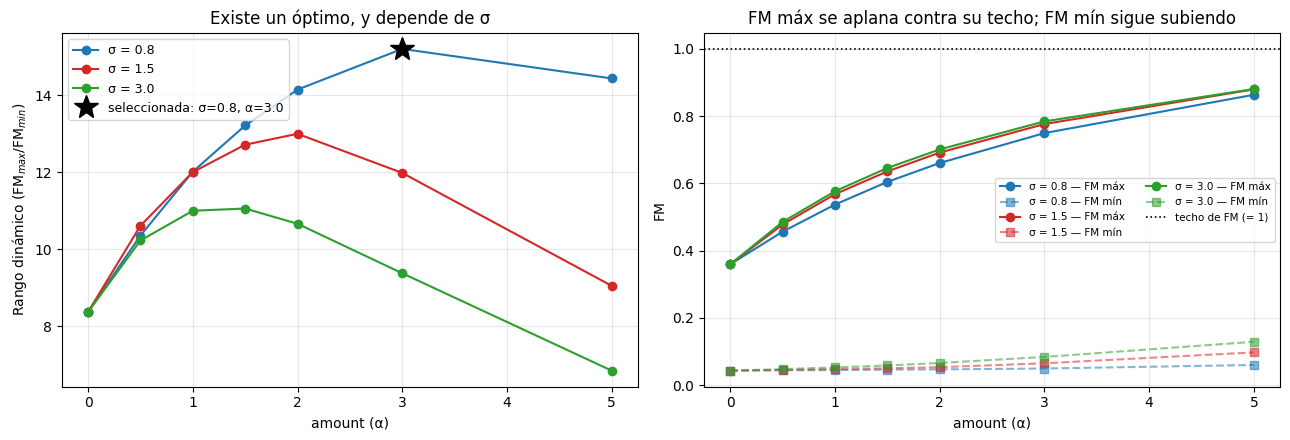

In [33]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

for s, color in zip(sigmas_us, ["#1f77b4", "#d62728", "#2ca02c"]):
    ax1.plot(amounts, [r["rango"] for r in resultados[s]], "o-", color=color, label=f"σ = {s}")
    ax2.plot(amounts, [r["max"] for r in resultados[s]], "o-", color=color, label=f"σ = {s} — FM máx")
    ax2.plot(amounts, [r["min"] for r in resultados[s]], "s--", color=color, alpha=0.55,
             label=f"σ = {s} — FM mín")

ax1.plot(AMOUNT_US, mejor["rango"], "*", color="k", ms=18, zorder=5,
         label=f"seleccionada: σ={SIGMA_US}, α={AMOUNT_US}")
ax1.set_xlabel("amount (α)"); ax1.set_ylabel("Rango dinámico (FM$_{max}$/FM$_{min}$)")
ax1.set_title("Existe un óptimo, y depende de σ")
ax1.legend(fontsize=9)

ax2.axhline(1.0, color="k", ls=":", lw=1.2, label="techo de FM (= 1)")
ax2.set_xlabel("amount (α)"); ax2.set_ylabel("FM")
ax2.set_title("FM máx se aplana contra su techo; FM mín sigue subiendo")
ax2.legend(fontsize=7.5, ncol=2)
plt.tight_layout(); plt.show()

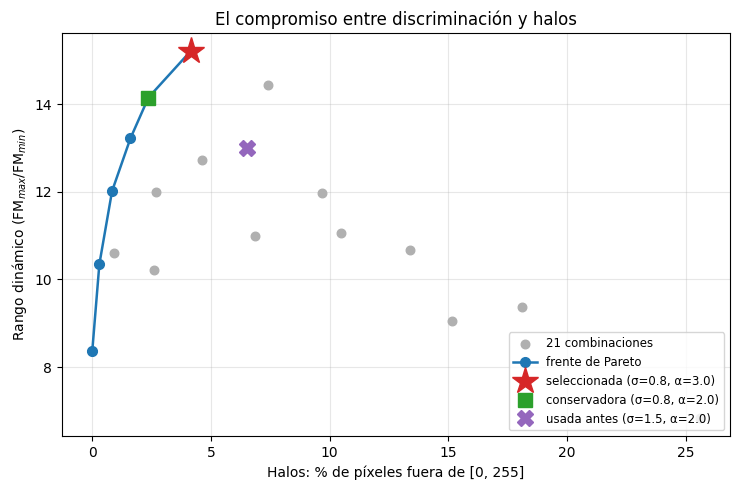

In [34]:
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter([r["halos"] * 100 for r in todas], [r["rango"] for r in todas],
           s=38, color="#b0b0b0", label="21 combinaciones", zorder=2)
ax.plot([r["halos"] * 100 for r in pareto_unico], [r["rango"] for r in pareto_unico],
        "o-", color="#1f77b4", lw=1.8, ms=7, label="frente de Pareto", zorder=3)
ax.plot(mejor["halos"] * 100, mejor["rango"], "*", color="#d62728", ms=20, zorder=5,
        label=f"seleccionada (σ={mejor['sigma']}, α={mejor['amount']})")
ax.plot(conservadora["halos"] * 100, conservadora["rango"], "s", color="#2ca02c", ms=10, zorder=5,
        label=f"conservadora (σ={conservadora['sigma']}, α={conservadora['amount']})")
ax.plot(referencia["halos"] * 100, referencia["rango"], "X", color="#9467bd", ms=12, zorder=5,
        label=f"usada antes (σ={referencia['sigma']}, α={referencia['amount']})")
ax.set_xlabel("Halos: % de píxeles fuera de [0, 255]")
ax.set_ylabel("Rango dinámico (FM$_{max}$/FM$_{min}$)")
ax.set_title("El compromiso entre discriminación y halos")
ax.legend(fontsize=8.5, loc="lower right")
plt.tight_layout(); plt.show()

**Hay un compromiso, y conviene nombrarlo.** La combinación seleccionada maximiza el rango dinámico,
que es el objetivo de la métrica: discriminar enfocado de desenfocado. Pero **no es la de menos
halos** del barrido — el frente de Pareto muestra varias opciones con menos halos y algo menos de
rango. En particular, la alternativa conservadora conserva el 93% del rango dinámico con el 57% de los
halos.

Se prioriza el rango dinámico porque en este TP el realce es **instrumental**: se aplica para mejorar
la medición del enfoque, no para producir un video de mejor calidad visual. Si el objetivo fuera
entregar el video para consumo humano, la elección correcta sería la conservadora.

Lo que sí es cierto sin matices es que la combinación seleccionada **mejora en las dos magnitudes a
la que se venía usando** antes de hacer este barrido: más rango dinámico y menos halos.

### 10.3 ⚠️ Por qué se calcula en punto flotante

La implementación directa con `cv2.addWeighted` sobre `uint8` **satura**: recorta a 0–255. Eso es un
problema para medir, porque **el recorte crea discontinuidades duras, que son exactamente las altas
frecuencias que la métrica cuenta**.

Conviene cuantificarlo **midiendo la saturación sobre la misma región donde se mide FM**, porque el
efecto depende fuertemente de la región: la ROI central es la zona de mayor detalle y por lo tanto la
que más se recorta, mientras que el frame completo promedia con áreas lisas.

In [35]:
regiones = {"ROI 10%": lambda im: roi_central(im, 0.10)[0],
            "Frame completo": lambda im: im}

filas_sat = []
for a in [0.5, 1.5, 2.0, 3.0]:
    realzada = unsharp_masking(frames[idx_ref], SIGMA_US, a)
    recortada = a_uint8(realzada)
    for nombre, recorte in regiones.items():
        r_float, r_uint8 = recorte(realzada), recorte(recortada)
        fm_f, fm_u = medida_enfoque(r_float), medida_enfoque(r_uint8)
        filas_sat.append({"region": nombre, "alpha": a,
                          "% saturado": 100 * fraccion_fuera_de_rango(r_float),
                          "FM float": fm_f, "FM uint8": fm_u,
                          "sesgo %": 100 * (fm_u / fm_f - 1)})

tabla_sat = pd.DataFrame(filas_sat).pivot(index="alpha", columns="region")
print(f"Unsharp masking con sigma={SIGMA_US}, sobre el frame {idx_ref}")
print("La saturacion se mide sobre LA MISMA region en la que se mide FM.\n")
print(tabla_sat.to_string(float_format=lambda v: f"{v:8.3f}"))

Unsharp masking con sigma=0.8, sobre el frame 109
La saturacion se mide sobre LA MISMA region en la que se mide FM.

           % saturado                FM float                FM uint8                 sesgo %         
region Frame completo  ROI 10% Frame completo  ROI 10% Frame completo  ROI 10% Frame completo  ROI 10%
alpha                                                                                                 
0.5             0.054    0.300          0.032    0.445          0.033    0.447          1.531    0.488
1.5             0.322    1.607          0.044    0.596          0.043    0.597         -3.286    0.160
2.0             0.507    2.367          0.053    0.654          0.049    0.658         -7.805    0.591
3.0             0.959    4.143          0.075    0.743          0.062    0.743        -17.155   -0.006


🔑 **La magnitud del sesgo depende fuertemente de la región.** Sobre la ROI 10% se mantiene por
debajo del **0,6%** para todas las ganancias probadas; sobre el frame completo crece con $\alpha$
hasta **−17,2%**, unas treinta veces más. El signo además no es estable: es positivo con ganancias
chicas y negativo con ganancias grandes.

La asimetría tiene explicación. La ROI central es la zona de mayor detalle: ahí el recorte satura
muchos más píxeles (4,1% contra 1,0% del frame completo en $\alpha = 3$) pero lo hace sobre bordes
que ya eran de alta frecuencia, así que el conteo espectral casi no cambia. En el frame completo
predominan zonas lisas, donde el recorte **aplasta** el realce justo en las pocas regiones con
detalle, y el efecto neto es una pérdida apreciable de altas frecuencias.

Esto **refuerza** la decisión de trabajar en punto flotante: no es una precaución cosmética. Si el
realce se hubiera medido en `uint8` sobre el frame completo —uno de los dos experimentos que pide la
consigna— el error habría llegado al 17%.

In [36]:
frames_sharp = [unsharp_masking(f, SIGMA_US, AMOUNT_US) for f in frames]
fm_roi_sharp = curva_fm(frames_sharp, lambda f: roi_central(f, 0.10)[0])

d_base = deteccion["ROI 10%"]
d_sharp = detectar_region_enfoque(fm_roi_sharp)

for etq, curva, d in [("original", fm_roi[0.10], d_base), ("realzada", fm_roi_sharp, d_sharp)]:
    print(f"ROI 10% {etq:9s}:  max={curva.max():.4f}  min={curva.min():.4f}  "
          f"rango={curva.max()/curva.min():.2f}x  pico={d['pico']}  "
          f"región=[{d['inicio']},{d['fin']}] ({(d['fin']-d['inicio']+1)/FPS:.2f}s)")

print(f"\nAumento medio de FM: {100*(fm_roi_sharp.mean()/fm_roi[0.10].mean() - 1):+.1f}%")
print(f"Factor de amplificación del máximo: {fm_roi_sharp.max()/fm_roi[0.10].max():.2f}x")
print(f"Factor de amplificación del mínimo: {fm_roi_sharp.min()/fm_roi[0.10].min():.2f}x")

ROI 10% original :  max=0.3594  min=0.0429  rango=8.37x  pico=111  región=[100,113] (0.47s)
ROI 10% realzada :  max=0.7496  min=0.0493  rango=15.21x  pico=111  región=[89,113] (0.83s)

Aumento medio de FM: +87.8%
Factor de amplificación del máximo: 2.09x
Factor de amplificación del mínimo: 1.15x


### 10.4 Efecto visual y halos

Frame de transición (primero con FM ≥ 50% del máximo): 79


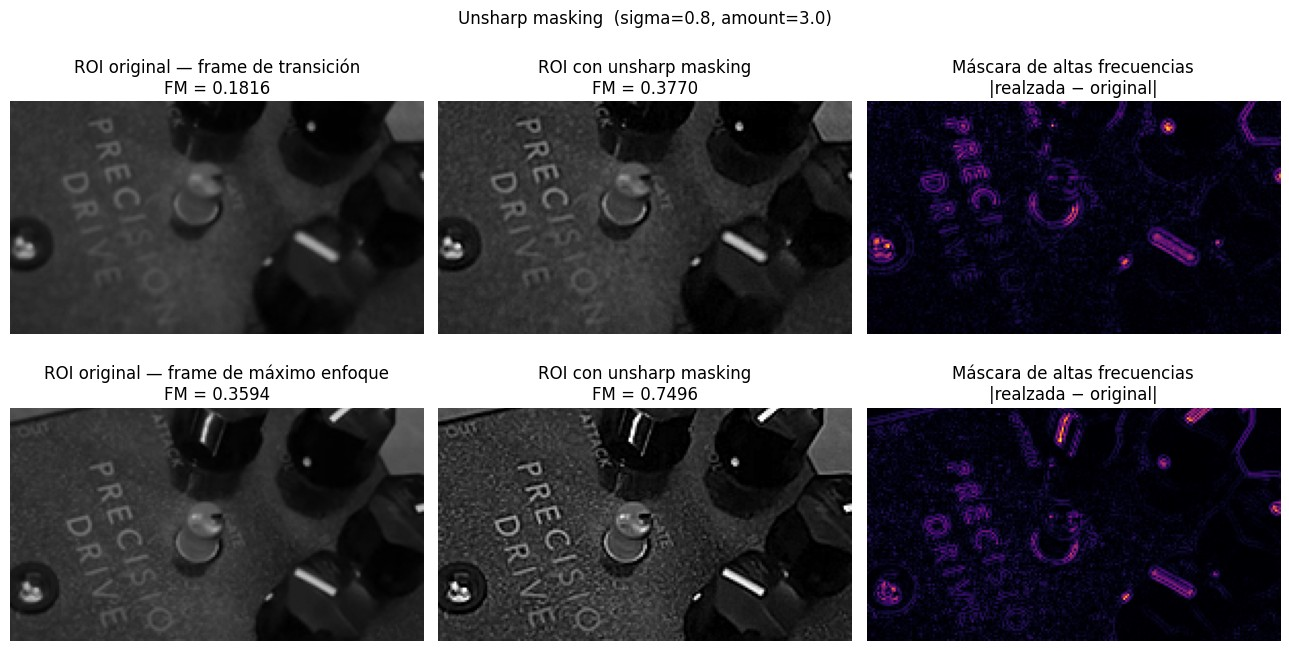

In [37]:
# Frame de transición elegido automáticamente: el primero cuyo FM alcanza la mitad del máximo.
idx_trans = int(np.argmax(fm_roi[0.10] >= 0.5 * fm_roi[0.10].max()))
print(f"Frame de transición (primero con FM ≥ 50% del máximo): {idx_trans}")

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for fila, (idx, etq) in enumerate([(idx_trans, "frame de transición"),
                                   (d_base["pico"], "frame de máximo enfoque")]):
    orig, _ = roi_central(frames[idx], 0.10)
    real, _ = roi_central(frames_sharp[idx], 0.10)

    axes[fila, 0].imshow(orig, cmap="gray", vmin=0, vmax=255)
    axes[fila, 0].set_title(f"ROI original — {etq}\nFM = {medida_enfoque(orig):.4f}")
    axes[fila, 1].imshow(a_uint8(real), cmap="gray", vmin=0, vmax=255)
    axes[fila, 1].set_title(f"ROI con unsharp masking\nFM = {medida_enfoque(real):.4f}")
    axes[fila, 2].imshow(np.abs(real - orig), cmap="inferno")
    axes[fila, 2].set_title("Máscara de altas frecuencias\n|realzada − original|")
    for c in range(3):
        axes[fila, c].axis("off")

plt.suptitle(f"Unsharp masking  (sigma={SIGMA_US}, amount={AMOUNT_US})", y=0.99)
plt.tight_layout(); mostrar_jpeg(fig)

El realce introduce **halos** —sobreimpulso a ambos lados de un borde fuerte—. Conviene mirarlos en
un perfil de intensidad en lugar de declarar de memoria que no se ven.

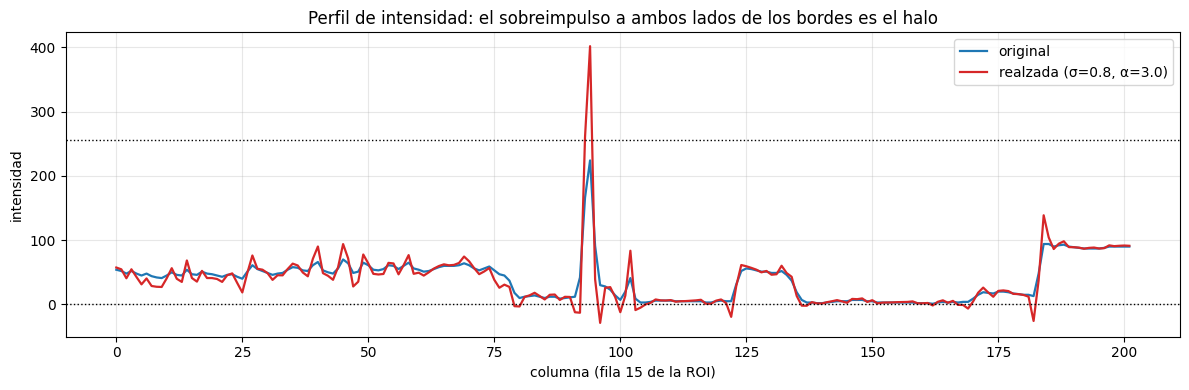

Halos en la ROI del frame 111 (ambos medidos sobre el mismo frame):
  seleccionada  sigma=0.8, alpha=3.0: 4.09% de píxeles fuera de [0,255]
  usada antes   sigma=1.5, alpha=2.0: 6.51%


In [38]:
roi_o, _ = roi_central(frames[d_base["pico"]], 0.10)
roi_s, _ = roi_central(frames_sharp[d_base["pico"]], 0.10)
fila = int(np.argmax(np.abs(np.diff(roi_o.astype(float), axis=1)).max(axis=1)))

fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(roi_o.shape[1])
ax.plot(x, roi_o[fila], color="#1f77b4", lw=1.6, label="original")
ax.plot(x, roi_s[fila], color="#d62728", lw=1.6, label=f"realzada (σ={SIGMA_US}, α={AMOUNT_US})")
ax.axhline(0, color="k", ls=":", lw=1); ax.axhline(255, color="k", ls=":", lw=1)
ax.set_xlabel(f"columna (fila {fila} de la ROI)"); ax.set_ylabel("intensidad")
ax.set_title("Perfil de intensidad: el sobreimpulso a ambos lados de los bordes es el halo")
ax.legend()
plt.tight_layout(); plt.show()

roi_ref_alt, _ = roi_central(
    unsharp_masking(frames[d_base["pico"]], referencia["sigma"], referencia["amount"]), 0.10)
print(f"Halos en la ROI del frame {d_base['pico']} (ambos medidos sobre el mismo frame):")
print(f"  seleccionada  sigma={SIGMA_US}, alpha={AMOUNT_US}: "
      f"{fraccion_fuera_de_rango(roi_s):.2%} de píxeles fuera de [0,255]")
print(f"  usada antes   sigma={referencia['sigma']}, alpha={referencia['amount']}: "
      f"{fraccion_fuera_de_rango(roi_ref_alt):.2%}")

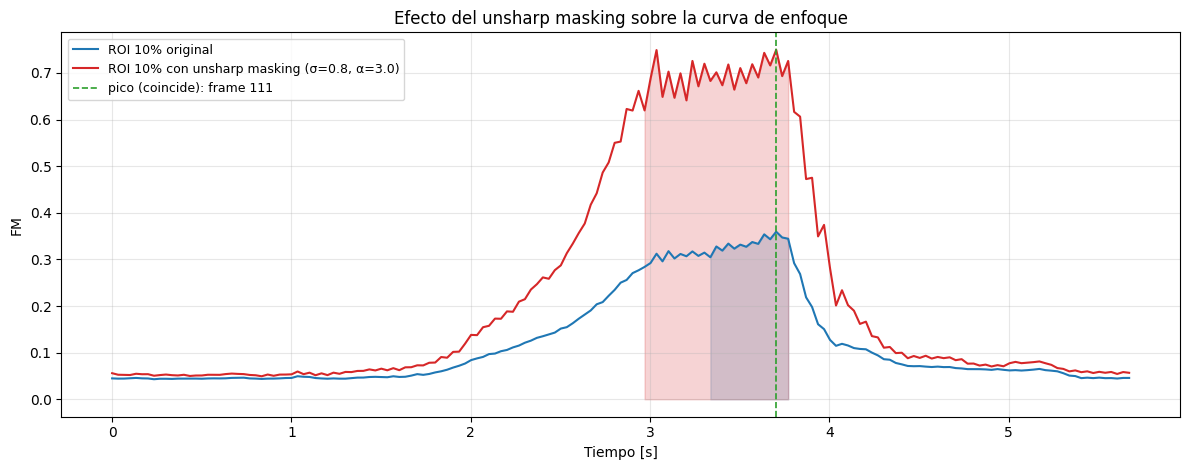

In [39]:
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(t, fm_roi[0.10], color="#1f77b4", lw=1.5, label="ROI 10% original")
ax.plot(t, fm_roi_sharp, color="#d62728", lw=1.5,
        label=f"ROI 10% con unsharp masking (σ={SIGMA_US}, α={AMOUNT_US})")
ax.fill_between(t, 0, fm_roi[0.10], where=d_base["mascara"], color="#1f77b4", alpha=0.20)
ax.fill_between(t, 0, fm_roi_sharp, where=d_sharp["mascara"], color="#d62728", alpha=0.20)
ax.axvline(t[d_base["pico"]], color="#2ca02c", ls="--", lw=1.2,
           label=f"pico (coincide): frame {d_base['pico']}")
ax.set_xlabel("Tiempo [s]"); ax.set_ylabel("FM")
ax.set_title("Efecto del unsharp masking sobre la curva de enfoque")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()

### 10.5 Análisis del realce

**1. El realce expande efectivamente la zona de enfoque.** La región detectada sobre la ROI 10% se
ensancha de 0,47 s a 0,83 s y el rango dinámico sube de 8,4x a 15,2x. Es lo que pide el enunciado.

**2. Por qué se ensancha.** El realce no sube todos los frames por igual: el máximo se amplifica
bastante más que el mínimo (los factores están impresos arriba). Es lo esperable, porque el unsharp
masking **amplifica las altas frecuencias en proporción a las que ya existen**: un frame cercano al
foco tiene bastante contenido de alta frecuencia y se beneficia mucho; uno completamente borroso
tiene poco y casi no cambia. La meseta se levanta más que el piso y más frames superan el umbral
relativo.

**3. Existe un óptimo, y es saturación de la métrica, no ruido.** Para cada $\sigma$ el rango
dinámico crece con $\alpha$, llega a un máximo y después cae. Es tentador atribuir la caída a que el
realce amplifica el ruido del sensor, pero el panel derecho del gráfico del barrido muestra una
explicación más simple y más fuerte: **FM está acotada por 1 y se está acercando a su techo**. Con
$\alpha = 5$ el máximo llega a ~0,88 —el 88% de los coeficientes ya superan el umbral— y el numerador
casi no tiene a dónde crecer, mientras el piso sigue subiendo sin límite. El cociente máx/mín
**tiene que** caer por pura aritmética, haya ruido o no. La consecuencia práctica: **la métrica
pierde poder discriminante a medida que se acerca a 1**, y conviene operar lejos de ese régimen.

**4. $\sigma$ importa tanto como $\alpha$.** El barrido lo confirma: un $\sigma$ chico realza detalle
fino, sube FM rápido y alcanza su óptimo con ganancia más alta; uno grande realza estructura más
gruesa y tiene menos efecto sobre el conteo espectral. Por eso los parámetros del video entregado se
eligen **del barrido y no a mano**.

**5. Hay halos, y son medibles.** El perfil de intensidad muestra el sobreimpulso característico a
ambos lados de los bordes, y una fracción de píxeles se sale del rango representable. No es
despreciable: es el costo visual del realce. La combinación seleccionada **no es la de menos halos**
del barrido —el frente de Pareto de la sección 10.2 muestra opciones que cambian algo de rango
dinámico por bastantes menos halos—, pero sí mejora en ambas magnitudes a la que se usaba antes de
hacer el barrido. Se priorizó el rango dinámico porque acá el realce es instrumental para medir, no
para producir un video de consumo visual.

**6. El límite del método.** El pico **no se corre**: el frame de máximo enfoque es el mismo en las
21 combinaciones de $\sigma$ y $\alpha$ probadas, incluso en el régimen saturado. Esto es correcto y
deseable —el realce no debe inventar un óptimo— pero marca su alcance:

> El unsharp masking amplifica las altas frecuencias **que sobrevivieron** a la captura; no puede
> recuperar las que el desenfoque óptico eliminó.

Lo que se expande es la **zona que la métrica considera aceptablemente nítida**, no la profundidad de
campo del video.

### 10.6 Entrega del video realzado

El enunciado pide "expandir la zona de enfoque **y devolver**". Se escribe a disco el video completo
con el realce aplicado, usando los parámetros que eligió el barrido.

In [40]:
salida_video = SALIDA / "focus_video_realzado.mp4"
writer = cv2.VideoWriter(str(salida_video), cv2.VideoWriter_fourcc(*"mp4v"),
                         FPS, (W, H), isColor=False)
if not writer.isOpened():
    raise IOError("No se pudo abrir el VideoWriter")
for f in frames_sharp:
    writer.write(a_uint8(f))
writer.release()

print(f"Video realzado escrito en: {salida_video}  ({salida_video.stat().st_size/1024:.0f} KB)")
print(f"Parámetros elegidos por el barrido: sigma={SIGMA_US}, amount={AMOUNT_US}")

Video realzado escrito en: salida\focus_video_realzado.mp4  (883 KB)
Parámetros elegidos por el barrido: sigma=0.8, amount=3.0


---
<a id="11"></a>
## 11. Conclusiones

1. **La métrica del paper se implementó fielmente y se validó por tres vías.** Los seis pasos de la
   sección 3.1 se trasladan uno a uno a `medida_enfoque`; la ecuación (1) se verificó contra el
   ejemplo numérico de *Lena* que publica el propio paper; y el barrido de desenfoque gaussiano
   reproduce el decrecimiento monótono de su figura 5(a).

2. **FM no es comparable entre regiones de distinto tamaño**, aunque la división por $M \cdot N$
   sugiera lo contrario. Con el mismo contenido visual remuestreado, FM varía un orden de magnitud.
   Por eso todas las comparaciones de esta entrega se hacen por **rango dinámico y forma**, nunca por
   nivel absoluto.

3. **El detector es completamente automático y su pico es robusto.** `detectar_region_enfoque` no
   recibe ningún índice de frame, y la misma función con los mismos parámetros resuelve los tres
   casos. El pico detectado **no cambia** para umbrales del 80% al 99%, y coincide con el `argmax`
   crudo, lo que confirma que no es un outlier.

4. **El ancho de la región, en cambio, no es robusto, y el trabajo lo reporta en lugar de
   ocultarlo.** La curva de la ROI 10% tiene un hombro donde la pendiente es cuatro veces menor que
   en el flanco de bajada, y cinco frames consecutivos quedan a menos de 1,7 puntos porcentuales del
   umbral sin cruzarlo, lo que vuelve el borde inferior mal condicionado. Se verificó que **no se
   arregla con histéresis**, y por un motivo preciso: el hombro entero está por debajo del umbral, de
   modo que el crecimiento de la región nunca entra en él y no hay cruce que tolerar. La salida
   confiable del detector es el pico; el intervalo es indicativo.

5. **Medir sobre una ROI central es superior a medir sobre el cuadro completo, y el mecanismo no es
   el que parece.** El control a igual número de píxeles (frame completo remuestreado a 202×114:
   3,67x contra 8,37x de la ROI) demuestra que la ventaja viene **del recorte y no del tamaño**. Y la
   medición de regiones de fondo muestra que **el fondo no aporta un piso constante: entra en foco en
   otro instante** (picos en los frames 69 y 118, contra 111 del sujeto). La curva del cuadro
   completo es la **superposición de picos desplazados** correspondientes a distintas profundidades:
   por eso su meseta es más ancha y su pico aparece corrido. Medir sobre todo el cuadro no diluye la
   señal, **mide otra magnitud** —el enfoque promedio de la escena— que no es la que el autofoco
   necesita.

6. **La robustez demostrada es frente al umbral, no frente al preprocesamiento.** Ventanear con Hann
   antes de la FFT elimina el leakage espectral, **triplica el rango dinámico y corre el pico 12
   frames**. Como la ventana además re-pondera el contenido hacia el centro, con lo medido no se
   puede afirmar cuál pico es "el correcto". Los resultados reportados son los del algoritmo tal como
   lo define el paper, que es lo que pide la consigna; el ventaneo queda como análisis de
   sensibilidad.

7. **El unsharp masking expande la zona de enfoque, con un límite claro.** Con los parámetros que
   elige el barrido (σ=0,8, α=3,0), ensancha la región de 0,47 s a 0,83 s y lleva el rango dinámico
   de 8,4x a **15,2x**, porque amplifica las altas frecuencias en proporción a las
   existentes y por lo tanto levanta la meseta más que el piso. El óptimo en $\alpha$ —que depende de
   $\sigma$— se explica por la **saturación de FM contra su techo de 1**, no por amplificación de
   ruido: el gráfico de FM máx vs. $\alpha$ lo muestra aplanándose. El pico se mantiene en el frame
   111 en las 21 combinaciones probadas: el realce mejora la medición, no la información óptica.

8. **Conexión con el autofoco real.** El procedimiento implementado es el de un autofoco por
   detección de contraste: se barre el plano focal, se mide una métrica de nitidez sobre una región
   acotada del sensor y se conserva la posición que la maximiza. El punto 5 muestra que esa región
   acotada no es un atajo computacional sino una necesidad: sin ella se estaría midiendo el enfoque
   promedio de toda la escena en lugar del enfoque del sujeto.